# Even-odd features from other mouse datasets (SFig 4)
Plotting clonal datasets from:
- Lrig1 oesephegus data from Piedrafita et al, Nature Comms 2020
- K14 tail skin (scale region) data from Sanchez-Danes et al, Nature 2016
- K14 backskin data from Aragona et al, Nature 2020

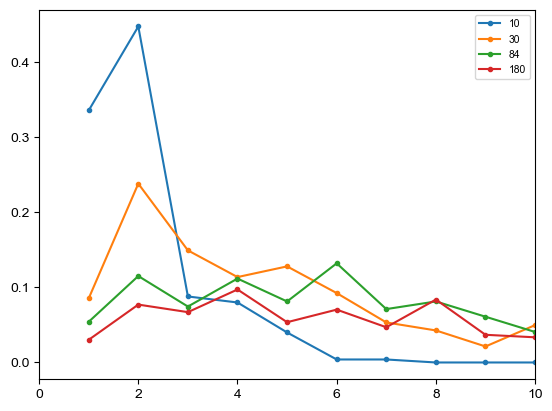

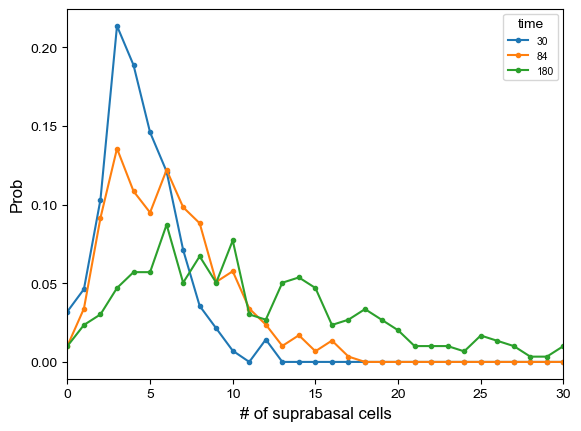

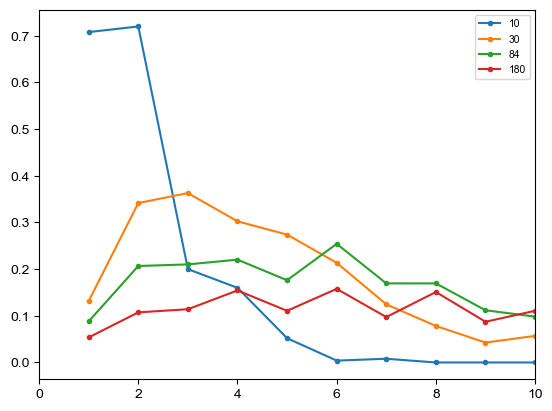

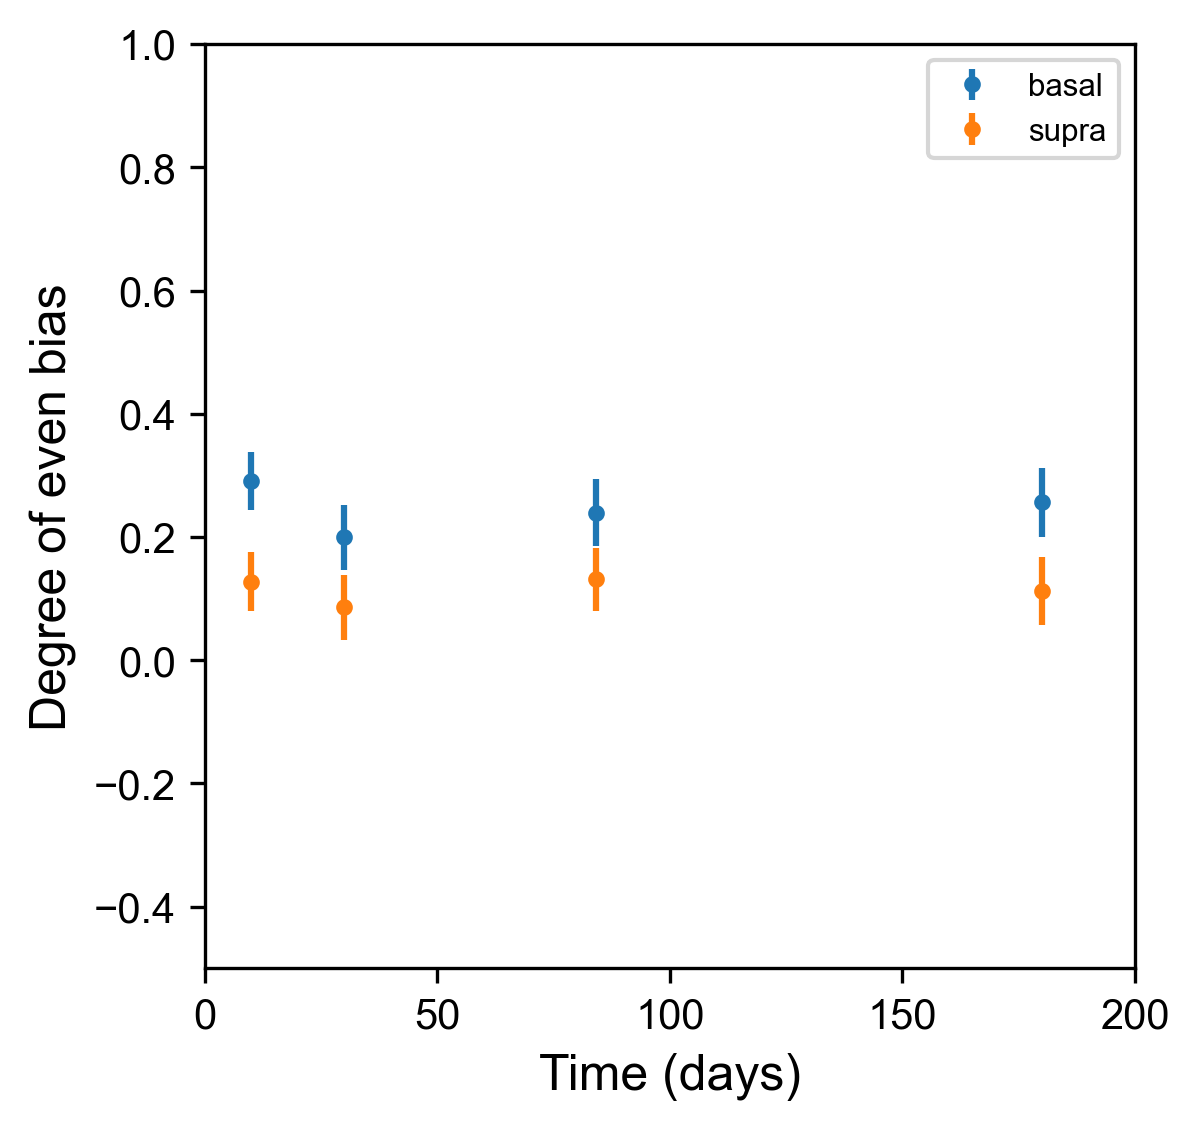

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")

filename = 'lrig1_oesephagus_processed.xlsx'

from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


def sefrac(f, n):
    fa = np.array(f)
    na = np.array(n)
    return np.sqrt(fa*(1-fa)/na)

# Control

tc = [10, 30, 84, 180]

cs_bas_ctr = []
nm_bas_ctr = []
av_bas_ctr = []
se_bas_ctr = []
ev_bas_ctr = []

cs_sup_ctr = []
nm_sup_ctr = []
av_sup_ctr = []
se_sup_ctr = []
ev_sup_ctr = []

cs_dif_ctr = []
nm_dif_ctr = []
av_dif_ctr = []
se_dif_ctr = []
ev_dif_ctr = []

cs_tot_ctr = []
nm_tot_ctr = []
av_tot_ctr = []
se_tot_ctr = []
mx_tot_ctr = []
ev_tot_ctr = []


sheet = 'Lrig1'

for d in tc:
    colname = 'D' + str(d) + ' '
    df = pd.read_excel(filename, sheet_name = sheet)
    bas = df[colname + 'B'].values[~np.isnan(df[colname + 'B'].values)]
    sup = df[colname + 'S'].values[~np.isnan(df[colname + 'S'].values)]
    dif = df[colname + 'D'].values[~np.isnan(df[colname + 'D'].values)]    
    tot = df[colname + 'T'].values[~np.isnan(df[colname + 'T'].values)]
    
    cs_bas_ctr.append(bas)
    nm_bas_ctr.append(len(bas))
    av_bas_ctr.append(np.mean(bas))
    se_bas_ctr.append(np.std(bas)/np.sqrt(len(bas)))
    ev_bas_ctr.append(np.mean(1 - (bas[bas > 0] % 2)))
    
    cs_sup_ctr.append(sup)
    nm_sup_ctr.append(len(sup))    
    av_sup_ctr.append(np.mean(sup))
    se_sup_ctr.append(np.std(sup)/np.sqrt(len(sup)))  
    ev_sup_ctr.append(np.mean(1 - (sup[sup > 0] % 2))) 
    
    cs_dif_ctr.append(dif)
    nm_dif_ctr.append(len(dif))    
    av_dif_ctr.append(np.mean(dif))
    se_dif_ctr.append(np.std(dif)/np.sqrt(len(dif)))  
    ev_dif_ctr.append(np.mean(1 - (dif[dif > 0] % 2)))    
    
    cs_tot_ctr.append(tot)
    nm_tot_ctr.append(len(tot))        
    av_tot_ctr.append(np.mean(tot))
    se_tot_ctr.append(np.std(tot)/np.sqrt(len(tot)))  
    mx_tot_ctr.append(np.max(tot))
    ev_tot_ctr.append(np.mean(1 - (tot[tot > 0] % 2)))    
    
maxbin = int(np.max(mx_tot_ctr)) + 1

cpdf = np.zeros((len(tc), 3, maxbin)) # index 1: basal, suprabasal, total
ccdf = np.zeros((len(tc), 3, maxbin))

for i in range(len(tc)):
    cpdf[i,0,:], bins =np.histogram(cs_bas_ctr[i], bins = np.arange(0, maxbin + 1), density = True)
    cpdf[i,1,:], bins =np.histogram(cs_sup_ctr[i], bins = np.arange(0, maxbin + 1), density = True)
    cpdf[i,2,:], bins =np.histogram(cs_tot_ctr[i], bins = np.arange(0, maxbin + 1), density = True)    
    ccdf[i,:,:] = np.cumsum(cpdf[i,:,::-1], axis = 1)[:,::-1] 
    
#csur = 1 - ccdf[:,:,0]
    
cpdf[:,2,:] = np.sum(cpdf[:,0:2,:],1)
    
#pdf, bins =np.histogram(cs_bas_ctr[5], bins = np.arange(1, np.max(cs_bas_ctr[5]) + 1), density = True)



#Basal clone-size
plt.figure()
for t in range(len(tc)):
    plt.plot(np.arange(1,maxbin), cpdf[t,0,1:], 'o-', label = tc[t])
    #plt.semilogy(np.arange(1,maxbin)/av_bas_ctr[t], cpdf[t,0,1:], 'o-', label = tc[t])
    
plt.legend()
plt.xlim([0,10])
plt.show()

#Suprabasal clone-size
plt.figure()
for t in range(1,len(tc)):
    plt.plot(np.arange(0,maxbin), cpdf[t,1,0:], 'o-', label = tc[t])
plt.legend(title = 'time')
plt.xlim([0,30])
plt.xlabel('# of suprabasal cells')
plt.ylabel('Prob')
plt.show()

#Total clone-size
plt.figure()
for t in range(len(tc)):
    #plt.semilogy(np.arange(1,maxbin)/av_tot_ctr[t], cpdf[t,2,1:], 'o-', label = tc[t])
    plt.plot(np.arange(1,maxbin), cpdf[t,2,1:], 'o-', label = tc[t])
    
plt.legend()
plt.xlim([0,10])
plt.show()


import sys
sys.path.append("../../")
import clones
import analysis



even_bas = np.array([analysis.evenbias(cs_bas_ctr[i], True) for i in range(len(tc))])
even_sup = np.array([analysis.evenbias(cs_sup_ctr[i], True) for i in range(len(tc))])

nboots = 1000
bs = np.zeros((nboots, len(tc),2))
for i in range(nboots):
    for j in range(len(tc)):
        bs[i,j,0] = analysis.evenbias(np.random.choice(cs_bas_ctr[j], size = len(cs_bas_ctr[j]), replace = True), True)
        bs[i,j,1] = analysis.evenbias(np.random.choice(cs_sup_ctr[j], size = len(cs_sup_ctr[j]), replace = True), True)

se_even_bas = np.std(bs[:, :, 0], axis = 0)
se_even_sup = np.std(bs[:, :, 1], axis = 0)

plt.figure(figsize=(4,4), dpi=300)
plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'supra')
plt.ylabel('Degree of even bias')
plt.xlabel('Time (days)')
plt.legend()
plt.xlim([0, 200])
plt.ylim([-0.5, 1])
plt.show()

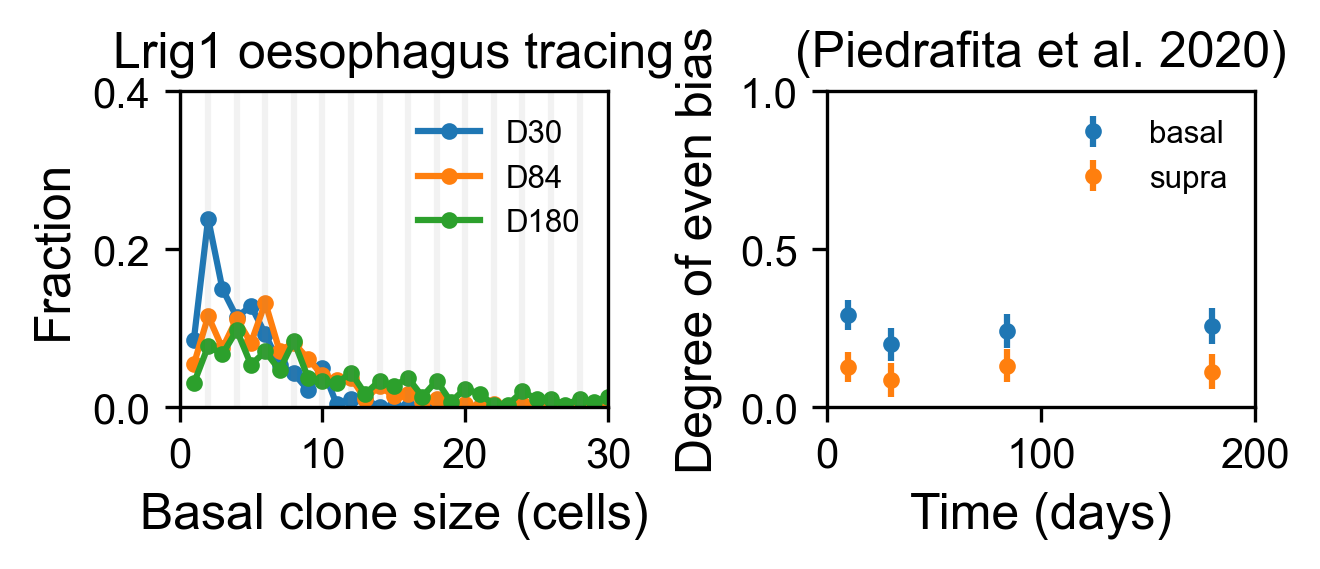

In [11]:
plt.figure(figsize=(4.5,2), dpi=300)
plt.subplot(1,2,1)
for t in range(1,len(tc)):
    #plt.semilogy(np.arange(1,maxbin)/av_tot_ctr[t], cpdf[t,2,1:], 'o-', label = tc[t])
    plt.plot(np.arange(1,maxbin), cpdf[t,0,1:], 'o-', label = f'D{tc[t]}')
plt.legend(frameon = False)
plt.xlabel('Basal clone size (cells)')
plt.ylabel('Fraction')
plt.title('Lrig1 oesophagus tracing')
plt.vlines(np.arange(0,30,2), 0, 1, colors = 'grey', alpha = 0.1)
plt.xlim([0,30])
plt.ylim([0,0.4])
plt.subplot(1,2,2)
plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'supra')
plt.ylabel('Degree of even bias')
plt.xlabel('Time (days)')
plt.legend(frameon = False)
plt.xlim([0, 200])
plt.ylim([0, 1])
plt.title('(Piedrafita et al. 2020)')
plt.tight_layout()
plt.savefig('Figures/Lrig1_Oesophagus.pdf', dpi=300, bbox_inches='tight')
plt.show()

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


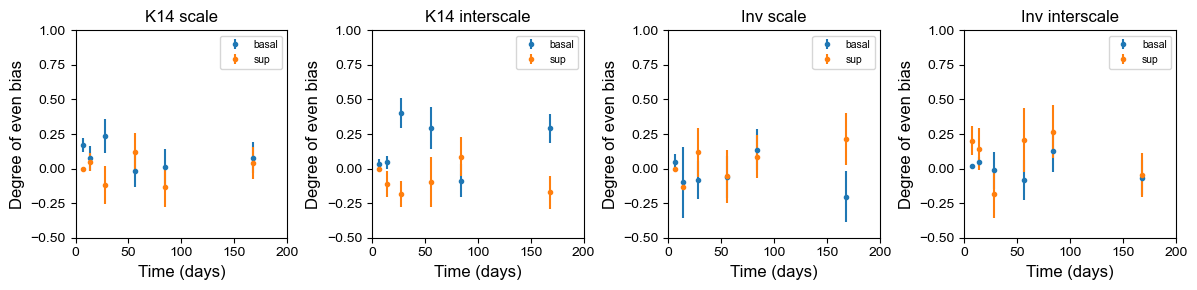

In [12]:
filename = 'sanchez-danes_control_data.xlsx'


# Control

def sefrac(f, n):
    fa = np.array(f)
    na = np.array(n)
    return np.sqrt(fa*(1-fa)/na)

tc = np.array([1,2,4,8,12,24])

cs_bas = {} 
nm_bas = {} 
av_bas = {} 
se_bas = {} 
ev_bas = {} 
nm_sup = {} 
cs_sup = {} 
av_sup = {} 
se_sup = {} 
ev_sup = {} 
cs_tot = {} 
nm_tot = {} 
av_tot = {} 
se_tot = {} 
mx_tot = {} 
ev_tot = {} 

cs_bas['K14_s'] = []
nm_bas['K14_s'] = []
av_bas['K14_s'] = []
se_bas['K14_s'] = []
ev_bas['K14_s'] = []
nm_sup['K14_s'] = []
cs_sup['K14_s'] = []
av_sup['K14_s'] = []
se_sup['K14_s'] = []
ev_sup['K14_s'] = []
cs_tot['K14_s'] = []
nm_tot['K14_s'] = []
av_tot['K14_s'] = []
se_tot['K14_s'] = []
mx_tot['K14_s'] = []
ev_tot['K14_s'] = []

cs_bas['K14_i'] = []
nm_bas['K14_i'] = []
av_bas['K14_i'] = []
se_bas['K14_i'] = []
ev_bas['K14_i'] = []
nm_sup['K14_i'] = []
cs_sup['K14_i'] = []
av_sup['K14_i'] = []
se_sup['K14_i'] = []
ev_sup['K14_i'] = []
cs_tot['K14_i'] = []
nm_tot['K14_i'] = []
av_tot['K14_i'] = []
se_tot['K14_i'] = []
mx_tot['K14_i'] = []
ev_tot['K14_i'] = []


cs_bas['Inv_i'] = []
nm_bas['Inv_i'] = []
av_bas['Inv_i'] = []
se_bas['Inv_i'] = []
ev_bas['Inv_i'] = []
nm_sup['Inv_i'] = []
cs_sup['Inv_i'] = []
av_sup['Inv_i'] = []
se_sup['Inv_i'] = []
ev_sup['Inv_i'] = []
cs_tot['Inv_i'] = []
nm_tot['Inv_i'] = []
av_tot['Inv_i'] = []
se_tot['Inv_i'] = []
mx_tot['Inv_i'] = []
ev_tot['Inv_i'] = []


cs_bas['Inv_s'] = []
nm_bas['Inv_s'] = []
av_bas['Inv_s'] = []
se_bas['Inv_s'] = []
ev_bas['Inv_s'] = []
nm_sup['Inv_s'] = []
cs_sup['Inv_s'] = []
av_sup['Inv_s'] = []
se_sup['Inv_s'] = []
ev_sup['Inv_s'] = []
cs_tot['Inv_s'] = []
nm_tot['Inv_s'] = []
av_tot['Inv_s'] = []
se_tot['Inv_s'] = []
mx_tot['Inv_s'] = []
ev_tot['Inv_s'] = []

maxbin = 1

for sheet in ['K14_s', 'K14_i', 'Inv_s', 'Inv_i']:
    for d in tc:
        colname = str(d) + 'W' +  ' '
        df = pd.read_excel(filename, sheet_name = sheet)
        bas = df[colname + 'Basal'].values[~np.isnan(df[colname + 'Basal'].values)].astype('int')
        sup = df[colname + 'Suprabasal'].values[~np.isnan(df[colname + 'Suprabasal'].values)].astype('int')
        tot = bas + sup

        cs_bas[sheet].append(bas)
        nm_bas[sheet].append(len(bas))
        av_bas[sheet].append(np.mean(bas))
        se_bas[sheet].append(np.std(bas)/np.sqrt(len(bas)))
        ev_bas[sheet].append(np.mean(1 - (bas[bas > 0] % 2)))

        cs_sup[sheet].append(sup)
        nm_sup[sheet].append(len(sup))    
        av_sup[sheet].append(np.mean(sup))
        se_sup[sheet].append(np.std(sup)/np.sqrt(len(sup)))  
        ev_sup[sheet].append(np.mean(1 - (sup[sup > 0] % 2))) 

        cs_tot[sheet].append(tot)
        nm_tot[sheet].append(len(tot))        
        av_tot[sheet].append(np.mean(tot))
        se_tot[sheet].append(np.std(tot)/np.sqrt(len(tot)))  
        mx_tot[sheet].append(np.max(tot))
        ev_tot[sheet].append(np.mean(1 - (tot[tot > 0] % 2)))   
        
    if np.max(mx_tot[sheet]) > maxbin - 1:
        maxbin = int(np.max(mx_tot[sheet])) + 1


        
if maxbin > 226:
    print('ERROR')
    

maxbin = 226
cpdf = {}
ccdf = {}
        
for sheet in ['K14_s', 'K14_i', 'Inv_s', 'Inv_i']:
    cpdf[sheet] = np.zeros((len(tc), 3, maxbin)) # index 1: basal, suprabasal, total
    ccdf[sheet] = np.zeros((len(tc), 3, maxbin))

    for i in range(len(tc)):
        cpdf[sheet][i,0,:], bins =np.histogram(cs_bas[sheet][i], bins = np.arange(0, maxbin + 1), density = True)
        cpdf[sheet][i,1,:], bins =np.histogram(cs_sup[sheet][i], bins = np.arange(0, maxbin + 1), density = True)
        cpdf[sheet][i,2,:], bins =np.histogram(cs_tot[sheet][i], bins = np.arange(0, maxbin + 1), density = True)    
        ccdf[sheet][i,:,:] = np.cumsum(cpdf[sheet][i,:,::-1], axis = 1)[:,::-1] 

import sys
sys.path.append("../../")
import clones
import analysis


plt.figure(figsize=(12, 3))

names = {'K14_s': 'K14 scale', 'K14_i': 'K14 interscale', 'Inv_s': 'Inv scale', 'Inv_i': 'Inv interscale'}

for sheet in ['K14_s', 'K14_i', 'Inv_s', 'Inv_i']:
    cs_bas_ctr = cs_bas[sheet]
    cs_sup_ctr = cs_sup[sheet]
    plt.subplot(1, 4, ['K14_s', 'K14_i', 'Inv_s', 'Inv_i'].index(sheet) + 1)
    plt.title(names[sheet])
    tc = np.array([1,2,4,8,12,24])*7
    even_bas = np.array([analysis.evenbias(cs_bas_ctr[i], True) for i in range(len(tc))])
    even_sup = np.array([analysis.evenbias(cs_sup_ctr[i], True) for i in range(len(tc))])

    nboots = 1000
    bs = np.zeros((nboots, len(tc),2))
    for i in range(nboots):
        for j in range(len(tc)):
            bs[i,j,0] = analysis.evenbias(np.random.choice(cs_bas_ctr[j], size = len(cs_bas_ctr[j]), replace = True), True)
            bs[i,j,1] = analysis.evenbias(np.random.choice(cs_sup_ctr[j], size = len(cs_sup_ctr[j]), replace = True), True)

    se_even_bas = np.std(bs[:, :, 0], axis = 0)
    se_even_sup = np.std(bs[:, :, 1], axis = 0)


    plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
    plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'sup')
    plt.ylabel('Degree of even bias')
    plt.xlabel('Time (days)')
    plt.legend()
    plt.xlim([0, 200])
    plt.ylim([-0.5, 1.0])
plt.tight_layout()
plt.show()

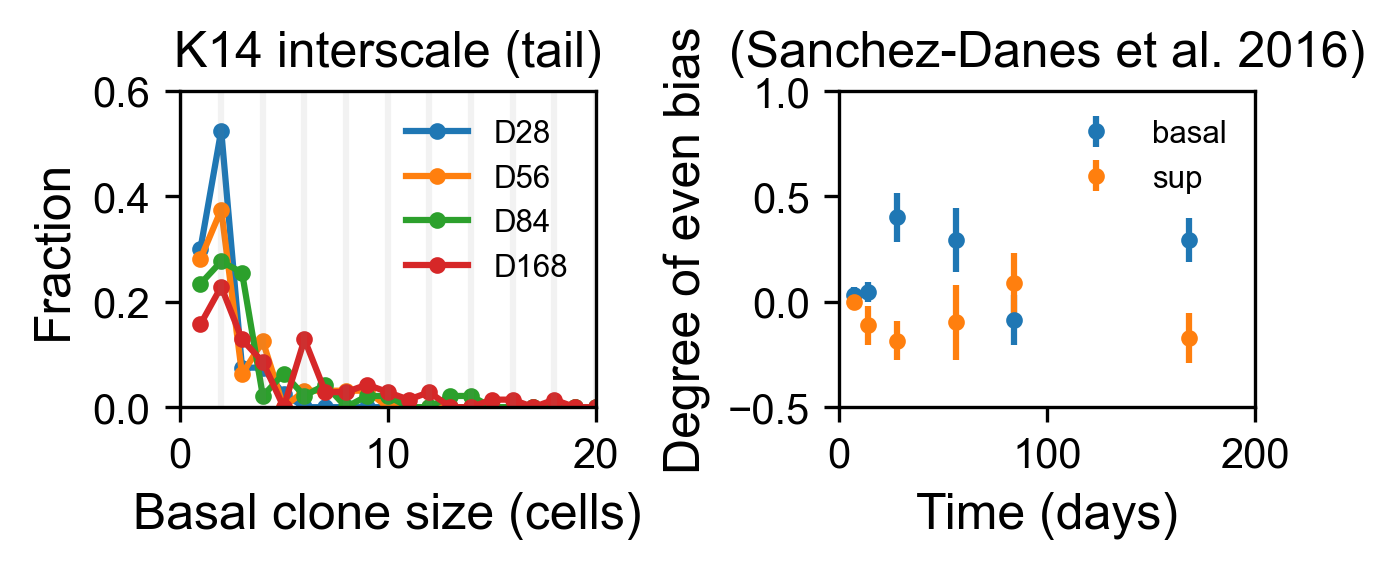

In [13]:

sheet = 'K14_i'
plt.figure(figsize=(4.5,2), dpi=300)
plt.subplot(1,2,1)
for t in range(2,len(tc)):
    plt.plot(np.arange(1,maxbin), cpdf[sheet][t,0,1:], 'o-', label = f'D{tc[t]}')
plt.legend(frameon = False)
plt.xlabel('Basal clone size (cells)')
plt.ylabel('Fraction')
plt.title('K14 interscale (tail)')
plt.vlines(np.arange(0,30,2), 0, 1, colors = 'grey', alpha = 0.1)
plt.xlim([0,20])
plt.ylim([0,0.6])
plt.subplot(1,2,2)

cs_bas_ctr = cs_bas[sheet]
cs_sup_ctr = cs_sup[sheet]
plt.subplot(1,2,2)
tc = np.array([1,2,4,8,12,24])*7
even_bas = np.array([analysis.evenbias(cs_bas_ctr[i], True) for i in range(len(tc))])
even_sup = np.array([analysis.evenbias(cs_sup_ctr[i], True) for i in range(len(tc))])

nboots = 1000
bs = np.zeros((nboots, len(tc),2))
for i in range(nboots):
    for j in range(len(tc)):
        bs[i,j,0] = analysis.evenbias(np.random.choice(cs_bas_ctr[j], size = len(cs_bas_ctr[j]), replace = True), True)
        bs[i,j,1] = analysis.evenbias(np.random.choice(cs_sup_ctr[j], size = len(cs_sup_ctr[j]), replace = True), True)

se_even_bas = np.std(bs[:, :, 0], axis = 0)
se_even_sup = np.std(bs[:, :, 1], axis = 0)


plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'sup')
plt.ylabel('Degree of even bias')
plt.xlabel('Time (days)')
plt.legend(frameon = False)
plt.xlim([0, 200])
plt.ylim([-0.5, 1.0])
plt.title('(Sanchez-Danes et al. 2016)')
plt.tight_layout()
plt.savefig('Figures/SD_tail.pdf', dpi=300, bbox_inches='tight')
plt.show()

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


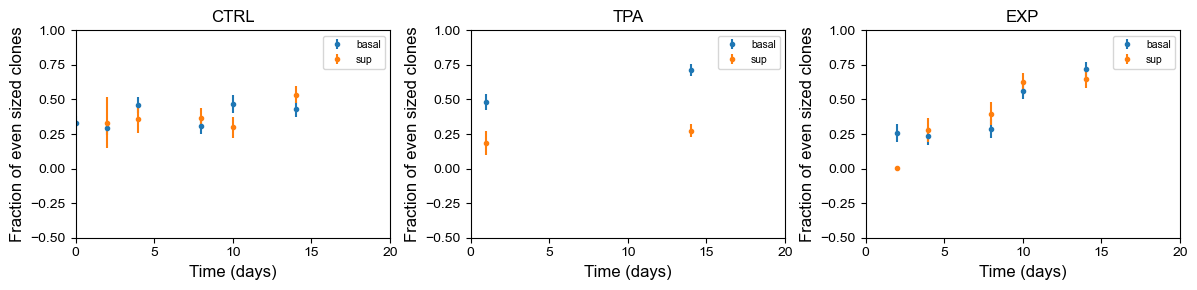

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


filename = 'aragona_data.xlsx'

def sefrac(f, n):
    fa = np.array(f)
    na = np.array(n)
    return np.sqrt(fa*(1-fa)/na)

# Control

tc = [0, 2, 4, 8, 10, 14]

cs_bas_ctr = []
nm_bas_ctr = []
av_bas_ctr = []
se_bas_ctr = []
ev_bas_ctr = []
nm_sup_ctr = []
cs_sup_ctr = []
av_sup_ctr = []
se_sup_ctr = []
ev_sup_ctr = []
cs_tot_ctr = []
nm_tot_ctr = []
av_tot_ctr = []
se_tot_ctr = []
mx_tot_ctr = []
ev_tot_ctr = []


etype = 'CTRL'
sheet = 'EXPAND CLONAL DATA'

for d in tc:
    colname = etype + ' D' + str(d) + ' '
    df = pd.read_excel(filename, sheet_name = sheet)
    bas = df[colname + 'B'].values[~np.isnan(df[colname + 'B'].values)]
    sup = df[colname + 'S'].values[~np.isnan(df[colname + 'S'].values)]
    tot = df[colname + 'T'].values[~np.isnan(df[colname + 'T'].values)]
    
    cs_bas_ctr.append(bas)
    nm_bas_ctr.append(len(bas))
    av_bas_ctr.append(np.mean(bas))
    se_bas_ctr.append(np.std(bas)/np.sqrt(len(bas)))
    ev_bas_ctr.append(np.mean(1 - (bas[bas > 0] % 2)))
    
    cs_sup_ctr.append(sup)
    nm_sup_ctr.append(len(sup))    
    av_sup_ctr.append(np.mean(sup))
    se_sup_ctr.append(np.std(sup)/np.sqrt(len(sup)))  
    ev_sup_ctr.append(np.mean(1 - (sup[sup > 0] % 2))) 
    
    cs_tot_ctr.append(tot)
    nm_tot_ctr.append(len(tot))        
    av_tot_ctr.append(np.mean(tot))
    se_tot_ctr.append(np.std(tot)/np.sqrt(len(tot)))  
    mx_tot_ctr.append(np.max(tot))
    ev_tot_ctr.append(np.mean(1 - (tot[tot > 0] % 2)))    
    
maxbin = int(np.max(mx_tot_ctr)) + 1

cpdf = np.zeros((len(tc), 3, maxbin)) # index 1: basal, suprabasal, total
ccdf = np.zeros((len(tc), 3, maxbin))

for i in range(len(tc)):
    cpdf[i,0,:], bins =np.histogram(cs_bas_ctr[i], bins = np.arange(0, maxbin + 1), density = True)
    cpdf[i,1,:], bins =np.histogram(cs_sup_ctr[i], bins = np.arange(0, maxbin + 1), density = True)
    cpdf[i,2,:], bins =np.histogram(cs_tot_ctr[i], bins = np.arange(0, maxbin + 1), density = True)    
    ccdf[i,:,:] = np.cumsum(cpdf[i,:,::-1], axis = 1)[:,::-1] 


even_bas = np.array([analysis.evenbias(cs_bas_ctr[i], True) for i in range(len(tc))])
even_sup = np.array([analysis.evenbias(cs_sup_ctr[i], True) for i in range(len(tc))])

nboots = 1000
bs = np.zeros((nboots, len(tc),2))
for i in range(nboots):
    for j in range(len(tc)):
        bs[i,j,0] = analysis.evenbias(np.random.choice(cs_bas_ctr[j], size = len(cs_bas_ctr[j]), replace = True), True)
        bs[i,j,1] = analysis.evenbias(np.random.choice(cs_sup_ctr[j], size = len(cs_sup_ctr[j]), replace = True), True)

se_even_bas = np.std(bs[:, :, 0], axis = 0)
se_even_sup = np.std(bs[:, :, 1], axis = 0)

plt.figure(figsize=(12, 3))
plt.subplot(1, 3, 1)
plt.title('CTRL')
plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'sup')
plt.ylabel('Fraction of even sized clones')
plt.xlabel('Time (days)')
plt.legend()
plt.xlim([0, 20])
plt.ylim([-0.5, 1.0])
#plt.show()


maxbin = int(np.max(mx_tot_ctr)) + 1

cpdf = np.zeros((len(tc), 3, maxbin)) # index 1: basal, suprabasal, total
ccdf = np.zeros((len(tc), 3, maxbin))

for i in range(len(tc)):
    cpdf[i,0,:], bins =np.histogram(cs_bas_ctr[i], bins = np.arange(0, maxbin + 1), density = True)
    cpdf[i,1,:], bins =np.histogram(cs_sup_ctr[i], bins = np.arange(0, maxbin + 1), density = True)
    cpdf[i,2,:], bins =np.histogram(cs_tot_ctr[i], bins = np.arange(0, maxbin + 1), density = True)    
    ccdf[i,:,:] = np.cumsum(cpdf[i,:,::-1], axis = 1)[:,::-1] 
    
#csur = 1 - ccdf[:,:,0]
    
cpdf[:,2,:] = np.sum(cpdf[:,0:2,:],1)


# control TPA

tt = [1, 14]

cs_bas_ctrT = []
av_bas_ctrT = []
cs_sup_ctrT = []
av_sup_ctrT = []
cs_tot_ctrT = []
av_tot_ctrT = []

etype = 'CTRL'
sheet = 'EXPAND CLONAL TPA'

for d in tt:
    
    colname = etype + '_D' + str(d) + ' '
    df = pd.read_excel(filename, sheet_name = sheet)
    bas = df[colname + 'B'].values[~np.isnan(df[colname + 'B'].values)]
    sup = df[colname + 'S'].values[~np.isnan(df[colname + 'S'].values)]
    tot = df[colname + 'T'].values[~np.isnan(df[colname + 'T'].values)]
    
    cs_bas_ctrT.append(bas)
    av_bas_ctrT.append(np.mean(bas))
    cs_sup_ctrT.append(sup)
    av_sup_ctrT.append(np.mean(sup))
    cs_tot_ctrT.append(tot)
    av_tot_ctrT.append(np.mean(tot))

tc = tt
even_bas = np.array([analysis.evenbias(cs_bas_ctrT[i], True) for i in range(len(tc))])
even_sup = np.array([analysis.evenbias(cs_sup_ctrT[i], True) for i in range(len(tc))])

nboots = 1000
bs = np.zeros((nboots, len(tc),2))
for i in range(nboots):
    for j in range(len(tc)):
        bs[i,j,0] = analysis.evenbias(np.random.choice(cs_bas_ctrT[j], size = len(cs_bas_ctr[j]), replace = True), True)
        bs[i,j,1] = analysis.evenbias(np.random.choice(cs_sup_ctrT[j], size = len(cs_sup_ctr[j]), replace = True), True)

se_even_bas = np.std(bs[:, :, 0], axis = 0)
se_even_sup = np.std(bs[:, :, 1], axis = 0)

#plt.figure(figsize=(12, 3))
plt.subplot(1, 3, 2)
plt.title('TPA')
plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'sup')
plt.ylabel('Fraction of even sized clones')
plt.xlabel('Time (days)')
plt.legend()
plt.xlim([0, 20])
plt.ylim([-0.5, 1.0])




# Experiment

te = [2, 4, 8, 10, 14]

cs_bas_exp = []
av_bas_exp = []
nm_bas_exp = []
ev_bas_exp = []

cs_sup_exp = []
av_sup_exp = []
nm_sup_exp = []
ev_sup_exp = []

cs_tot_exp = []
av_tot_exp = []
nm_tot_exp = []
ev_tot_exp = []


etype = 'EXP'
sheet = 'EXPAND CLONAL DATA'

for d in te:
    colname = etype + ' D' + str(d) + ' '
    df = pd.read_excel(filename, sheet_name = sheet)
    bas = df[colname + 'B'].values[~np.isnan(df[colname + 'B'].values)]
    sup = df[colname + 'S'].values[~np.isnan(df[colname + 'S'].values)]
    tot = df[colname + 'T'].values[~np.isnan(df[colname + 'T'].values)]
    
    cs_bas_exp.append(bas)
    nm_bas_exp.append(len(bas))
    av_bas_exp.append(np.mean(bas))
    ev_bas_exp.append(np.mean(1 - (bas[bas > 0] % 2)))
    
    cs_sup_exp.append(sup)
    nm_sup_exp.append(len(sup))    
    av_sup_exp.append(np.mean(sup))
    ev_sup_exp.append(np.mean(1 - (sup[sup > 0] % 2)))
    
    cs_tot_exp.append(tot)
    nm_tot_exp.append(len(tot))        
    av_tot_exp.append(np.mean(tot))
    ev_tot_exp.append(np.mean(1 - (tot[tot > 0] % 2)))

tc = te
even_bas = np.array([analysis.evenbias(cs_bas_exp[i], True) for i in range(len(tc))])
even_sup = np.array([analysis.evenbias(cs_sup_exp[i], True) for i in range(len(tc))])

nboots = 1000
bs = np.zeros((nboots, len(tc),2))
for i in range(nboots):
    for j in range(len(tc)):
        bs[i,j,0] = analysis.evenbias(np.random.choice(cs_bas_exp[j], size = len(cs_bas_ctr[j]), replace = True), True)
        bs[i,j,1] = analysis.evenbias(np.random.choice(cs_sup_exp[j], size = len(cs_sup_ctr[j]), replace = True), True)

se_even_bas = np.std(bs[:, :, 0], axis = 0)
se_even_sup = np.std(bs[:, :, 1], axis = 0)

#plt.figure(figsize=(12, 3))
plt.subplot(1, 3, 3)
plt.title('EXP')
plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'sup')
plt.ylabel('Fraction of even sized clones')
plt.xlabel('Time (days)')
plt.legend()
plt.xlim([0, 20])
plt.ylim([-0.5, 1.0])
plt.tight_layout()
plt.show()


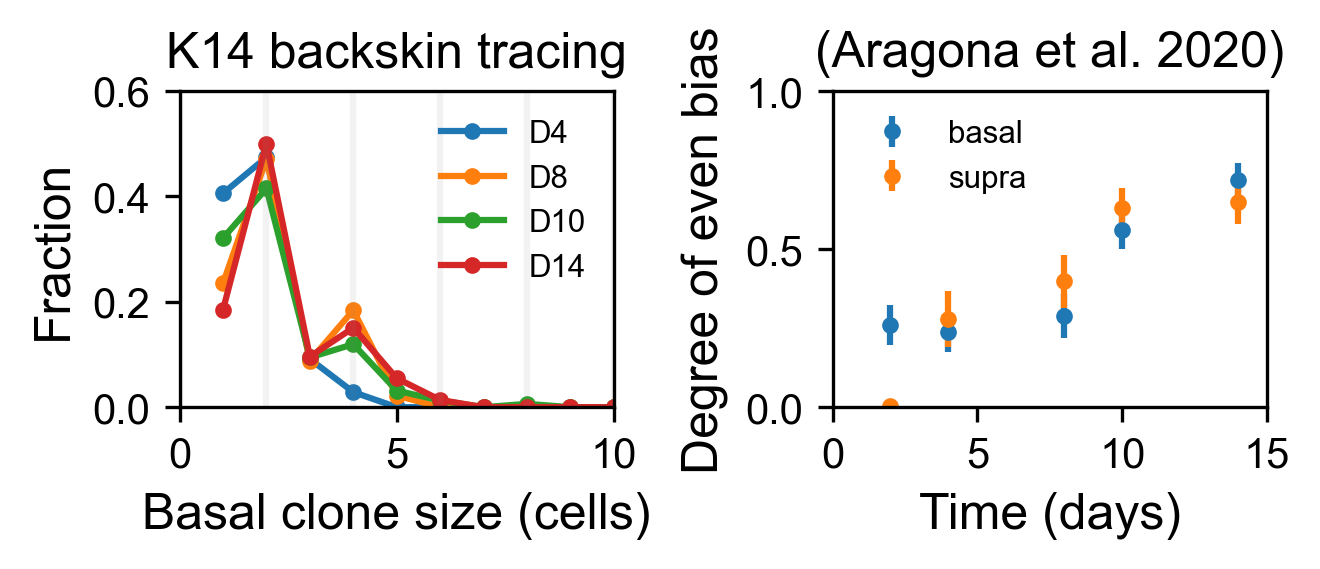

In [15]:
plt.figure(figsize=(4.5,2), dpi=300)
plt.subplot(1,2,1)
for t in range(1,len(tc)):
    #plt.semilogy(np.arange(1,maxbin)/av_tot_ctr[t], cpdf[t,2,1:], 'o-', label = tc[t])
    plt.plot(np.arange(1,maxbin), cpdf[t,0,1:], 'o-', label = f'D{tc[t]}')
plt.legend(frameon = False)
plt.xlabel('Basal clone size (cells)')
plt.ylabel('Fraction')
plt.title('K14 backskin tracing')
plt.vlines(np.arange(0,30,2), 0, 1, colors = 'grey', alpha = 0.1)
plt.xlim([0,10])
plt.ylim([0,0.6])
plt.subplot(1,2,2)
plt.errorbar(tc, even_bas, se_even_bas, fmt = 'o', label = 'basal')
plt.errorbar(tc, even_sup, se_even_sup, fmt = 'o', label = 'supra')
plt.ylabel('Degree of even bias')
plt.xlabel('Time (days)')
plt.legend(frameon = False)
plt.xlim([0, 15])
plt.ylim([0, 1])
plt.title('(Aragona et al. 2020)')
plt.tight_layout()
plt.savefig('Figures/backsin.pdf', dpi=300, bbox_inches='tight')
plt.show()